<center><h1>Blombach_George_HW5</h1></center>
<br>
<br>

Name: George Blombach
<br>
Github Username: gblombach
<br>
USC ID:  2416-0961-99

## 1. Decision Trees as Interpretable Models

In [1]:
import os
import numpy as np
import pandas as pd

from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree, _tree
from sklearn.model_selection import cross_val_score, StratifiedKFold, GridSearchCV, KFold
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_squared_error
from sklearn.linear_model import LinearRegression, RidgeCV, Lasso
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

import matplotlib.pyplot as plt
import seaborn as sns

from xgboost import XGBRegressor

### (a) Obtain Data

In [2]:
datapath = '../data/diagnosis.data'
columns = ['Temperature', 'Nausea', 'Lumbar_pain', 'Urine_pushing', 'Micturition_pain', 'Burning_urethra', 'Bladder', 'Nephritis']
# read data file to dataframe, and display
df = pd.read_csv(datapath, sep="\t", header=None, names=columns, decimal=",", encoding="utf-16")
df.head()

,Temperature,Nausea,Lumbar_pain,Urine_pushing,Micturition_pain,Burning_urethra,Bladder,Nephritis
0,35.5,no,yes,no,no,no,no,no
1,35.9,no,no,yes,yes,yes,yes,no
2,35.9,no,yes,no,no,no,no,no
3,36.0,no,no,yes,yes,yes,yes,no
4,36.0,no,yes,no,no,no,no,no


### (b) Build a decision tree

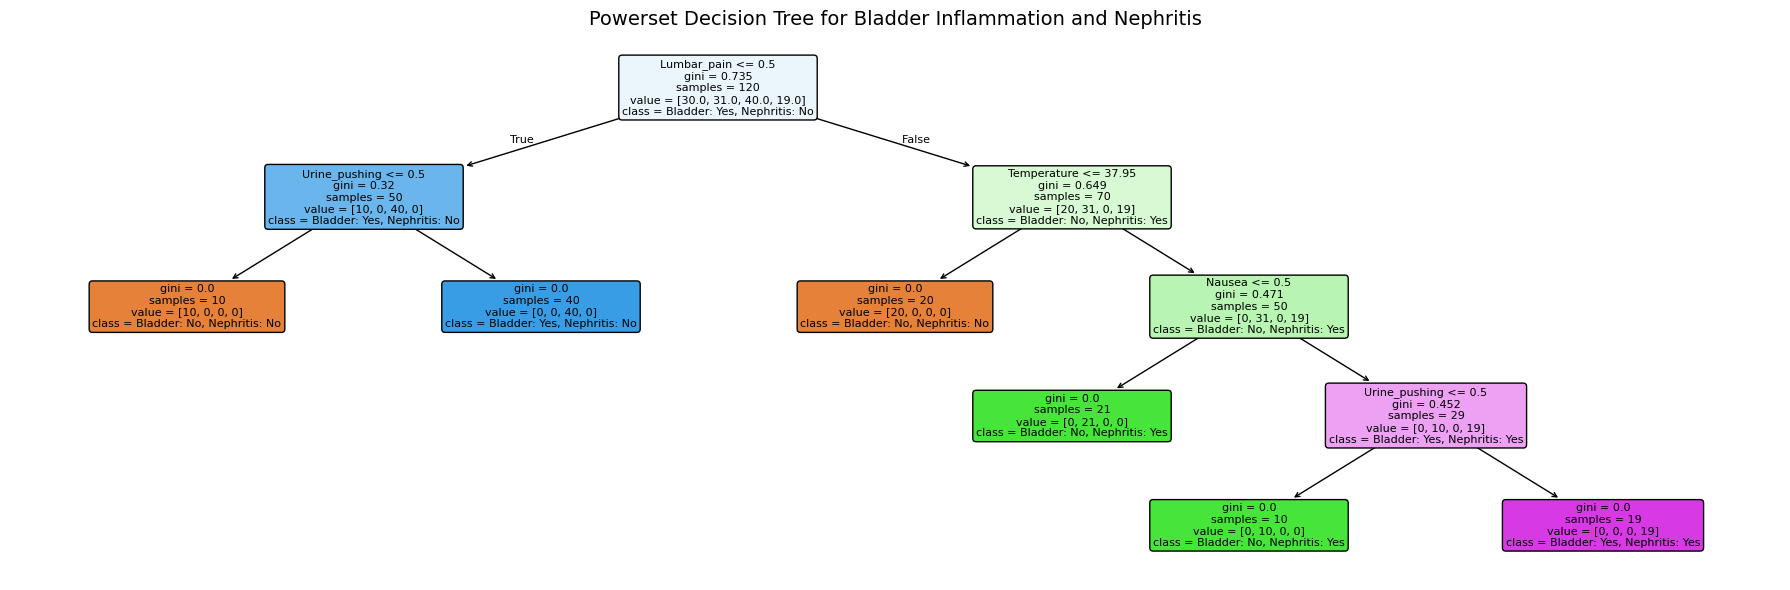

In [70]:
#replace Yes/No with 1/0 in dataframe copy
mapping = {'yes':1, 'no':0}
data = df.map(lambda x: mapping.get(x, x)).copy()
data.head()
# Define predictors and responses
responses = data.iloc[:, :6]
predictor_cols = ['Bladder', 'Nephritis'] #replaced with Diagnosis target in plot
predictors = data[predictor_cols]
binary_responses = responses.drop(columns=['Temperature']) #remove Tempurature from list
#print(responses)
#define diagnosis for powerset
class_map = {"0_0": "Bladder: No, Nephritis: No", "0_1": "Bladder: No, Nephritis: Yes", "1_0": "Bladder: Yes, Nephritis: No", "1_1": "Bladder: Yes, Nephritis: Yes"}
data['Diagnosis'] = (data[predictor_cols].astype(str).agg('_'.join, axis=1).map(class_map))
diagnosis = data['Diagnosis']
# Fit one multi-output decision tree on the entire dataset
tree = DecisionTreeClassifier(random_state=333)
#tree.fit(responses, predictors)
tree.fit(responses, diagnosis)
# Plot the fitted tree
plt.figure(figsize=(18, 6))
plot_tree(tree, feature_names=responses.columns, class_names=tree.classes_, filled=True, rounded=True, impurity=True, fontsize=8)
plt.title("Powerset Decision Tree for Bladder Inflammation and Nephritis",fontsize=14)
plt.tight_layout()
plt.show()

### (c) Convert the decision rules

In [41]:
def tree_to_code(model, binary_features, feature_names):
    tree_ = model.tree_
    feature_name = [feature_names[i] if i != _tree.TREE_UNDEFINED else None for i in tree_.feature]
    binary_features = binary_features #
    def recurse(node, conditions):
        # Decision node
        if tree_.feature[node] != _tree.TREE_UNDEFINED:
            name = feature_name[node]
            threshold = tree_.threshold[node]
            # Translate a binary 0/1 split into No/Yes
            if name in binary_features and np.isclose(threshold, 0.5):
                left_condition = f"{name} = No"
                right_condition = f"{name} = Yes"
            else:
                left_condition = f"{name} <= {threshold:.2f}"
                right_condition = f"{name} > {threshold:.2f}"
            # Left branch: split condition is true
            recurse(tree_.children_left[node], conditions + [left_condition])
            # Right branch: split condition is false
            recurse(tree_.children_right[node], conditions + [right_condition])
        # Terminal leaf
        else:
            class_index = np.argmax(tree_.value[node][0])
            predicted_class = model.classes_[class_index]
            print("IF")
            for i, condition in enumerate(conditions):
                if i == 0:
                    print(f"    {condition}")
                else:
                    print(f"AND {condition}")
            print(f"THEN Diagnosis = {predicted_class}\n")
    recurse(0, [])
tree_to_code(tree, binary_responses, list(responses.columns))

IF
    Lumbar_pain = No
AND Urine_pushing = No
THEN Diagnosis = Bladder: No, Nephritis: No

IF
    Lumbar_pain = No
AND Urine_pushing = Yes
THEN Diagnosis = Bladder: Yes, Nephritis: No

IF
    Lumbar_pain = Yes
AND Temperature <= 37.95
THEN Diagnosis = Bladder: No, Nephritis: No

IF
    Lumbar_pain = Yes
AND Temperature > 37.95
AND Nausea = No
THEN Diagnosis = Bladder: No, Nephritis: Yes

IF
    Lumbar_pain = Yes
AND Temperature > 37.95
AND Nausea = Yes
AND Urine_pushing = No
THEN Diagnosis = Bladder: No, Nephritis: Yes

IF
    Lumbar_pain = Yes
AND Temperature > 37.95
AND Nausea = Yes
AND Urine_pushing = Yes
THEN Diagnosis = Bladder: Yes, Nephritis: Yes



### (d) Pruning

In [29]:
path = tree.cost_complexity_pruning_path(responses, diagnosis)
ccp_alphas = path.ccp_alphas
print("Alphas:", ccp_alphas)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=333)
results = []
for alpha in ccp_alphas:
    candidate_tree = DecisionTreeClassifier(ccp_alpha=alpha)
    scores = cross_val_score(candidate_tree, responses, diagnosis, cv=cv, scoring="accuracy")
    # Fit on the whole dataset temporarily to record tree size
    candidate_tree.fit(responses, diagnosis)
    results.append({"ccp_alpha": alpha, "mean_cv_accuracy": scores.mean(),"standard_error": (scores.std(ddof=1) / np.sqrt(cv.get_n_splits())), "tree_depth": candidate_tree.get_depth(),"number_of_leaves": candidate_tree.get_n_leaves()})
pruning_results = pd.DataFrame(results)
pruning_results

Alphas: [0.         0.09816667 0.13333333 0.182      0.22291667]


,ccp_alpha,mean_cv_accuracy,standard_error,tree_depth,number_of_leaves
0,0.000000,0.991667,0.008333,4,6
1,0.098167,0.858333,0.036324,2,4
2,0.133333,0.766667,0.038640,2,3
3,0.182000,0.666667,0.029463,1,2
4,0.222917,0.483333,0.061237,0,1


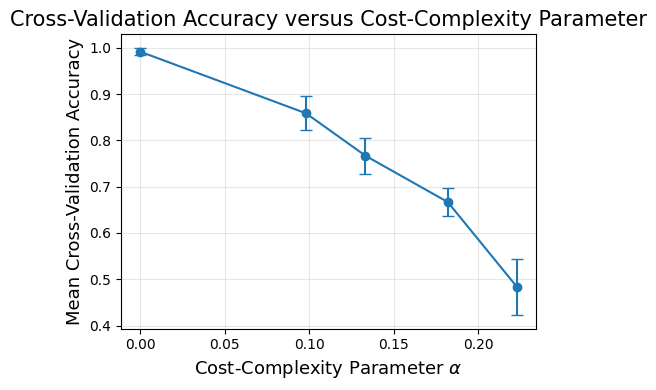

In [6]:
plt.figure(figsize=(5, 4))
plt.errorbar(pruning_results["ccp_alpha"], pruning_results["mean_cv_accuracy"], yerr=pruning_results["standard_error"], marker="o",capsize=4)
plt.xlabel(r"Cost-Complexity Parameter $\alpha$", fontsize=13)
plt.ylabel("Mean Cross-Validation Accuracy", fontsize=13)
plt.title("Cross-Validation Accuracy versus Cost-Complexity Parameter", fontsize=15)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [7]:
# remove trivial trees where tree depth = 0, and remove trees where alpha = 0
pruning_candidates = pruning_results[(pruning_results["number_of_leaves"] >= 2) & (pruning_results["ccp_alpha"] > 0)].copy()
print('Candidate trees are:')
pruning_candidates

Candidate trees are:


,ccp_alpha,mean_cv_accuracy,standard_error,tree_depth,number_of_leaves
1,0.098167,0.858333,0.036324,2,4
2,0.133333,0.766667,0.038640,2,3
3,0.182000,0.666667,0.029463,1,2


In [32]:
best_cv_accuracy = pruning_candidates["mean_cv_accuracy"].max()
best_trees = pruning_candidates[np.isclose(pruning_candidates["mean_cv_accuracy"],best_cv_accuracy)].copy()
selected_row = (best_trees.sort_values(by=["number_of_leaves", "tree_depth","ccp_alpha"], ascending=[True, True, False]).iloc[0])
selected_alpha = selected_row["ccp_alpha"]
print("Selected ccp_alpha:", selected_alpha,"\nMean CV accuracy:",round(selected_row["mean_cv_accuracy"], 4),"\nNumber of leaves:",int(selected_row["number_of_leaves"]),"\nTree depth:", int(selected_row["tree_depth"]))

Selected ccp_alpha: 0.09816666666666667 
Mean CV accuracy: 0.8583 
Number of leaves: 4 
Tree depth: 2


In [34]:
pruned_tree = DecisionTreeClassifier(ccp_alpha=selected_alpha)
pruned_tree.fit(responses, diagnosis)
print("Final tree depth:", pruned_tree.get_depth(),"\nFinal number of leaves:", pruned_tree.get_n_leaves(),"\nWhole-data accuracy:", round(pruned_tree.score(responses, diagnosis), 4))

Final tree depth: 2 
Final number of leaves: 4 
Whole-data accuracy: 0.8417


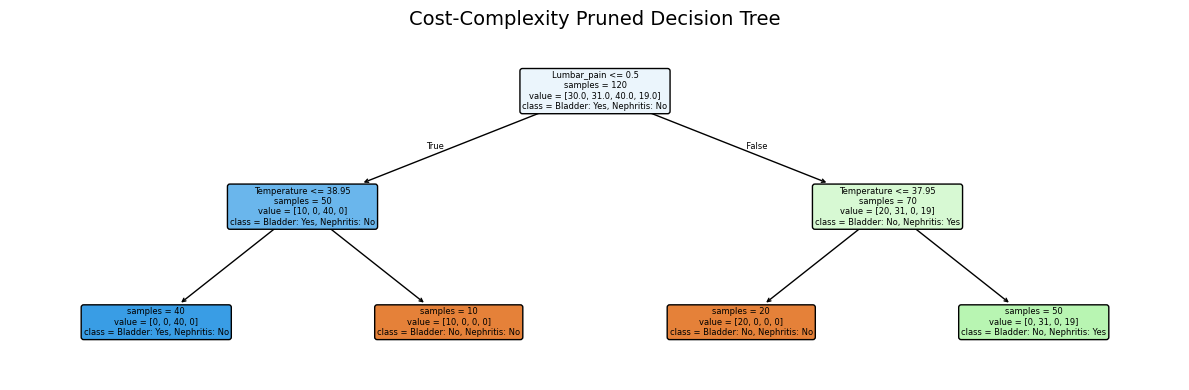

In [73]:
plt.figure(figsize=(12, 4))
plot_tree(pruned_tree, feature_names=responses.columns, class_names=[str(class_name) for class_name in pruned_tree.classes_], filled=True, rounded=True, impurity=False, fontsize=6)
plt.title("Cost-Complexity Pruned Decision Tree", fontsize=14)
plt.tight_layout()
plt.show()

In [11]:
#print IF-THEN for pruned tree
tree_to_code(pruned_tree, binary_responses, list(responses.columns))

IF
    Lumbar_pain = No
AND Temperature <= 38.95
THEN Diagnosis = Bladder: Yes, Nephritis: No

IF
    Lumbar_pain = No
AND Temperature > 38.95
THEN Diagnosis = Bladder: No, Nephritis: No

IF
    Lumbar_pain = Yes
AND Temperature <= 37.95
THEN Diagnosis = Bladder: No, Nephritis: No

IF
    Lumbar_pain = Yes
AND Temperature > 37.95
THEN Diagnosis = Bladder: No, Nephritis: Yes



## 2. The LASSO and Boosting for Regression

### (a) Obtain Data

Download the Communities and Crime data from https://archive.ics.uci.edu/ml/datasets/Communities+and+Crime. Use the first 1495 rows of data as the training set and the rest as the test set.


In [12]:
#first get attributes
attributes = []
with open('../data/communities.names', 'r') as file:
    for line in file:
        line = line.strip()
        if line.startswith('@attribute'):
            attribute = line.split()[1]
            attributes.append(attribute)
#print(attributes)
# then read communities data
communities_data = pd.read_csv('../data/communities.data', names=attributes, na_values='?')
#print(communities_data.head())

### (b) Missing values

In [13]:
#remove nonpredictive data
nonpredictive = ['state','county','community','communityname','fold']
#print(data.columns.tolist())
cleaned = communities_data.drop(columns=nonpredictive).copy()
#cleaned.head()
#define responses (X) and predictors (y)
X = cleaned.drop(columns="ViolentCrimesPerPop")
y = cleaned["ViolentCrimesPerPop"]
#split into test and training sets
X_train = X.iloc[:1495].copy()
X_test = X.iloc[1495:].copy()
y_train = y.iloc[:1495].copy()
y_test = y.iloc[1495:].copy()
print("X_train shape:", X_train.shape,"\nX_test shape:", X_test.shape,"\ny_train shape:", y_train.shape,"\ny_test shape:", y_test.shape)

X_train shape: (1495, 122)
X_test shape: (499, 122)
y_train shape: (1495,)
y_test shape: (499,)


In [36]:
print("Missing values in X_train before imputation:",X_train.isna().sum().sum(),"\nMissing values in X_test before imputation:",X_test.isna().sum().sum())

Missing values in X_train before imputation: 0 
Missing values in X_test before imputation: 0


In [38]:
# set imputer
imputer = SimpleImputer(strategy="median")
# fit imputer to train data, and transform test data
X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)
#convert back to dataframes
X_train = pd.DataFrame(X_train_imputed, columns=X.columns, index=X_train.index)
X_test = pd.DataFrame(X_test_imputed, columns=X.columns, index=X_test.index)
#check on changes
print("Missing values in X_train after imputation:",X_train.isna().sum().sum(),"\nMissing values in X_test after imputation:",X_test.isna().sum().sum())
print("Missing y_train values:", y_train.isna().sum(),"\nMissing y_test values:", y_test.isna().sum())

Missing values in X_train after imputation: 0 
Missing values in X_test after imputation: 0
Missing y_train values: 0 
Missing y_test values: 0


### (c) Plot a correlation matrix

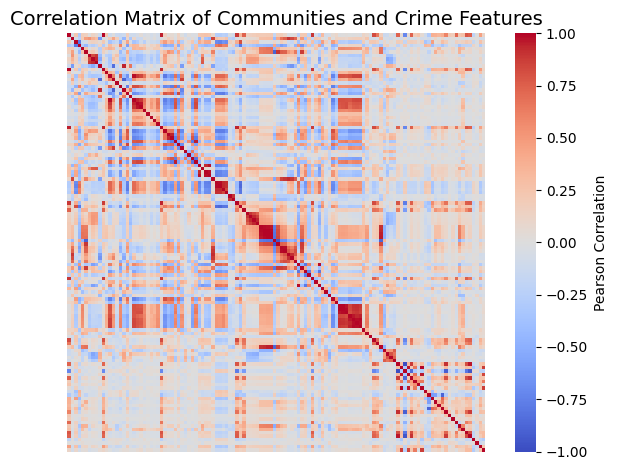

In [57]:
#combine the imputed training and test predictors before calculating the correlation matrix
X_imputed = pd.concat([X_train, X_test],axis=0).sort_index()
# Calculate the correlation matrix
correlation_matrix = X_imputed.corr()
sns.heatmap(correlation_matrix,cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True, xticklabels=False, yticklabels=False,cbar_kws={"label": "Pearson Correlation"})
plt.title("Correlation Matrix of Communities and Crime Features",fontsize=14)
plt.tight_layout()
plt.show()

### (d) Calculate the Coefficient of Variation CV

In [17]:
# Sample mean of each feature
feature_means = X_imputed.mean()
# Sample standard deviation of each feature
# ddof=1 makes this the sample standard deviation
feature_std = X_imputed.std(ddof=1)
# Coefficient of variation
cv = feature_std / feature_means
# Replace undefined values caused by a zero mean
cv = cv.replace([np.inf, -np.inf], np.nan)
# Create a results table
cv_results = pd.DataFrame({"Mean": feature_means,"Sample Standard Deviation": feature_std,"CV": cv})
# Sort from highest to lowest CV
cv_results = cv_results.sort_values(by="CV", ascending=False)
cv_results.head()

,Mean,Sample Standard Deviation,CV
PctPolicAsian,0.018375,0.100105,5.447835
NumStreet,0.022778,0.100400,4.407702
NumInShelters,0.029438,0.102607,3.485481
NumIlleg,0.036294,0.108671,2.994196
NumImmig,0.030060,0.087189,2.900497


### (e) Scatter plots and box plots for highest CV features

In [18]:
# Remove undefined CV values before selecting features
valid_cv_results = cv_results.dropna(subset=["CV"])
# Select the names of the 11 features with the highest CV
top_11_features = (valid_cv_results.nlargest(11, "CV").index.tolist())
print("11 features with the highest CV:\n")
for rank, feature in enumerate(top_11_features, start=1):
    print(f"{rank}. {feature}: "f"CV = {cv_results.loc[feature, 'CV']:.6f}")
#reconstruct response 
y_full = pd.concat([y_train, y_test]).sort_index()
# Confirm that predictors and response have matching indices
print( "\nIndices match:", X_imputed.index.equals(y_full.index))

11 features with the highest CV:

1. PctPolicAsian: CV = 5.447835
2. NumStreet: CV = 4.407702
3. NumInShelters: CV = 3.485481
4. NumIlleg: CV = 2.994196
5. NumImmig: CV = 2.900497
6. LemasPctOfficDrugUn: CV = 2.555266
7. NumUnderPov: CV = 2.304970
8. population: CV = 2.203503
9. LemasSwornFT: CV = 2.080712
10. numbUrban: CV = 2.001744
11. HousVacant: CV = 1.958780

Indices match: True


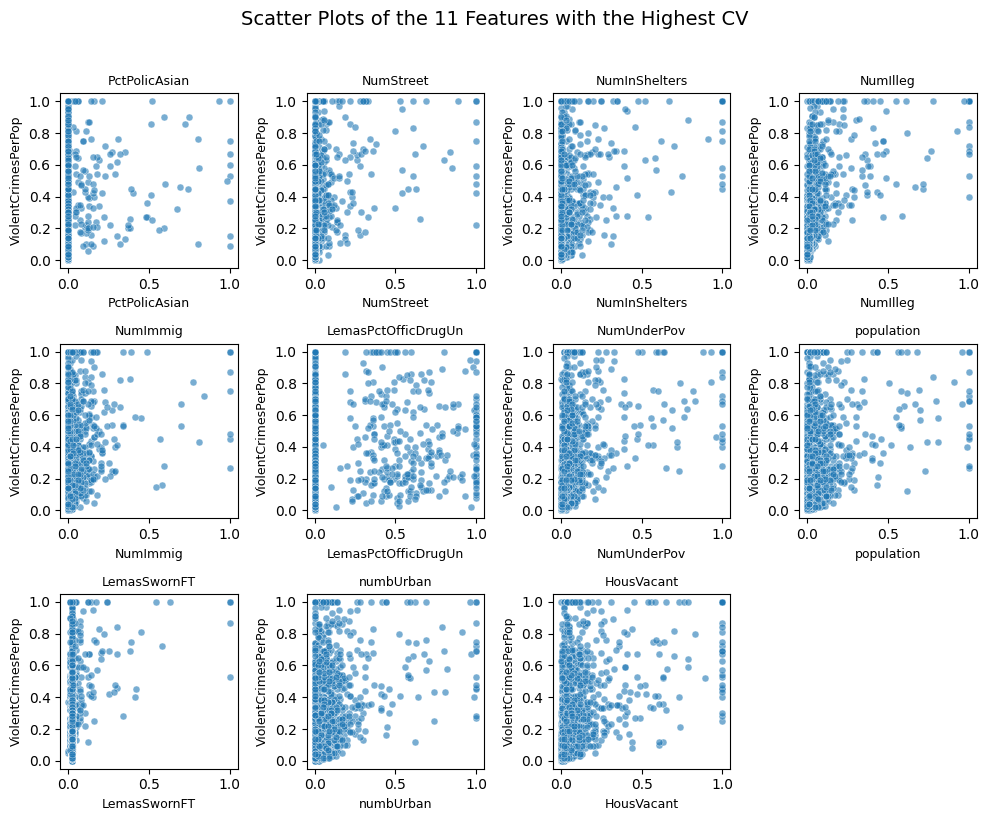

In [64]:
#make scatter plots
fig, axes = plt.subplots(nrows=3, ncols=4, figsize=(10, 8))
axes = axes.flatten()
for i, feature in enumerate(top_11_features):
    sns.scatterplot(x=X_imputed[feature], y=y_full,  ax=axes[i], s=25, alpha=0.6)
    axes[i].set_title(feature, fontsize=9)
    axes[i].set_xlabel(feature, fontsize=9)
    axes[i].set_ylabel("ViolentCrimesPerPop", fontsize=9)
# Remove the unused 12th subplot
for i in range(len(top_11_features), len(axes)):
    fig.delaxes(axes[i])
plt.suptitle("Scatter Plots of the 11 Features with the Highest CV", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

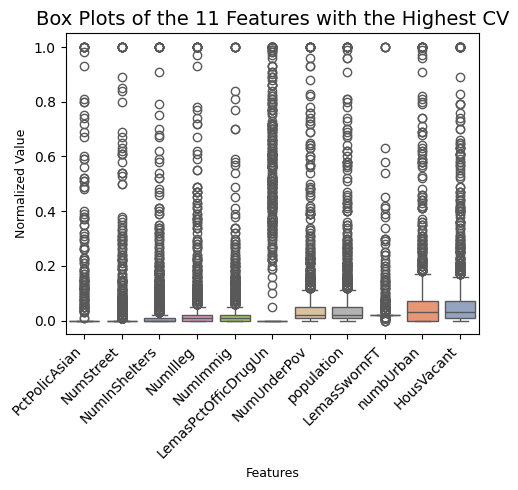

In [68]:
# make box plot with all 11 features
plt.figure(figsize=(5, 5))
sns.boxplot(data=X_imputed[top_11_features], palette="Set2")
plt.title("Box Plots of the 11 Features with the Highest CV",fontsize=14)
plt.xlabel("Features", fontsize=9)
plt.ylabel("Normalized Value", fontsize=9)
plt.xticks(rotation=45,ha="right")
plt.tight_layout()
plt.show()

##### Conclusion
No, I cannot determine from the scatter plots alone if there is a statistical significance.
The scatter plots can tell me if a relationship appears positive or negative, linear or nonlinear,
or if the relationship is weak or strong, but it is difficult to determine from the visualization 
things like coefficient estimates, standard errors, or p-values.

### (f) Fit a linear model

In [21]:
# Fit linear regression using least squares
lm = LinearRegression()
lm.fit(X_train, y_train)
# Predict on the test set
y_pred = lm.predict(X_test)
# Calculate test error (MSE)
test_error = mean_squared_error(y_test, y_pred)
print("Test MSE:", test_error)

Test MSE: 0.017966215426067335


### (g) Fit a ridge regression model

In [39]:
# Candidate lambda values
lambdas = np.logspace(-4, 4, 100)
# Ridge regression with cross-validation
ridge = Pipeline([("scaler", StandardScaler()),("ridge", RidgeCV(alphas=lambdas, cv=5))])
# Fit using training data only
ridge.fit(X_train, y_train)
# Best lambda selected by cross-validation
best_lambda = ridge.named_steps["ridge"].alpha_
# Predict test data
y_pred_ridge = ridge.predict(X_test)
# Calculate test MSE
ridge_test_mse = mean_squared_error(y_test, y_pred_ridge)
print("Best lambda:", best_lambda,"\nRidge Test MSE:", ridge_test_mse)

Best lambda: 79.24828983539186 
Ridge Test MSE: 0.017431130507402397


### (h) Fit a LASSO model

In [23]:
# Cross-validation settings and candidate lambda values
cv = KFold(n_splits=5,shuffle=True,random_state=333)
lambdas = np.logspace(-5, 1, 100)
# LASSO WITHOUT STANDARDIZATION
lasso_unstandardized = GridSearchCV(estimator=Lasso(max_iter=100000), param_grid={"alpha": lambdas}, scoring="neg_mean_squared_error", cv=cv, n_jobs=-1)
# Fit on the training set
lasso_unstandardized.fit(X_train, y_train)
# Best lambda chosen by cross-validation
best_lambda_unstandardized = (lasso_unstandardized.best_params_["alpha"])
# Predict the test set
y_pred_unstandardized = lasso_unstandardized.predict(X_test)
# Calculate test MSE
test_mse_unstandardized = mean_squared_error(y_test,y_pred_unstandardized)
# Extract coefficients from the best model
coef_unstandardized = pd.Series(lasso_unstandardized.best_estimator_.coef_,index=X_train.columns)
# Variables with nonzero coefficients are selected
selected_unstandardized = coef_unstandardized[~np.isclose(coef_unstandardized, 0)].sort_values(key=np.abs, ascending=False)
# LASSO WITH STANDARDIZATION
lasso_standardized_pipeline = Pipeline([("scaler", StandardScaler()),("lasso", Lasso(max_iter=100000))])
lasso_standardized = GridSearchCV(estimator=lasso_standardized_pipeline,param_grid={"lasso__alpha": lambdas}, scoring="neg_mean_squared_error",cv=cv, n_jobs=-1)
# Fit on the training set
lasso_standardized.fit(X_train, y_train)
# Best lambda chosen by cross-validation
best_lambda_standardized = (lasso_standardized.best_params_["lasso__alpha"])
# The pipeline standardizes X_test using training-set parameters
y_pred_standardized = lasso_standardized.predict(X_test)
# Calculate test MSE
test_mse_standardized = mean_squared_error(y_test, y_pred_standardized)
# Extract LASSO coefficients from the best pipeline
coef_standardized = pd.Series(lasso_standardized.best_estimator_.named_steps["lasso"].coef_, index=X_train.columns)
# Variables with nonzero coefficients are selected
selected_standardized = coef_standardized[~np.isclose(coef_standardized, 0)].sort_values(key=np.abs, ascending=False)
# REPORT RESULTS
print("LASSO WITHOUT STANDARDIZATION","\n--------------------------------")
print(f"Best lambda: {best_lambda_unstandardized:.10f}")
print(f"Test MSE: {test_mse_unstandardized:.10f}")
print(f"Number of selected variables: {len(selected_unstandardized)}")
#print("\nSelected variables:")
#print(selected_unstandardized)
print("\nLASSO WITH STANDARDIZATION")
print("--------------------------------")
print(f"Best lambda: {best_lambda_standardized:.10f}")
print(f"Test MSE: {test_mse_standardized:.10f}")
print(f"Number of selected variables: {len(selected_standardized)}")
#print("\nSelected variables:")
#print(selected_standardized)
# COMPARE TEST ERRORS
comparison = pd.DataFrame({"Model": ["LASSO without standardization","LASSO with standardization"],"Best Lambda": [best_lambda_unstandardized, best_lambda_standardized],
    "Test MSE": [test_mse_unstandardized, test_mse_standardized],"Number of Selected Variables": [len(selected_unstandardized),len(selected_standardized)]})
print("\nMODEL COMPARISON")
print("--------------------------------")
print(comparison.to_string(index=False))
if test_mse_standardized < test_mse_unstandardized:
    print("\nThe standardized LASSO model produced the lower test error.")
elif test_mse_standardized > test_mse_unstandardized:
    print("\nThe unstandardized LASSO model produced the lower test error.")
else:
    print("\nThe two models produced the same test error.")

LASSO WITHOUT STANDARDIZATION
--------------------------------
Best lambda: 0.0005722368
Test MSE: 0.0175471778
Number of selected variables: 31


LASSO WITH STANDARDIZATION
--------------------------------
Best lambda: 0.0035111917
Test MSE: 0.0174357116
Number of selected variables: 33


MODEL COMPARISON
--------------------------------
                        Model  Best Lambda  Test MSE  Number of Selected Variables
LASSO without standardization     0.000572  0.017547                            31
   LASSO with standardization     0.003511  0.017436                            33

The standardized LASSO model produced the lower test error.


### (i) Fit a PCR model

In [42]:
# 5-fold cross-validation
cv = KFold(n_splits=5, shuffle=True, random_state=333)
# PCR pipeline:1. Standardize the predictors, 2. Perform PCA, 3. Fit linear regression using the principal components
pcr_pipeline = Pipeline([("scaler", StandardScaler()),("pca", PCA()),("linear_regression", LinearRegression())])
# Try different numbers of principal components
max_components = min(X_train.shape[0], X_train.shape[1])
param_grid = {"pca__n_components": range(1, max_components + 1)}
# Choose M using cross-validation on the training set
pcr_cv = GridSearchCV(estimator=pcr_pipeline, param_grid=param_grid, scoring="neg_mean_squared_error", cv=cv, n_jobs=-1)
# Fit PCR model
pcr_cv.fit(X_train, y_train)
# Best number of principal components
best_M = pcr_cv.best_params_["pca__n_components"]
# Predict test set
y_pred_pcr = pcr_cv.predict(X_test)
# Test error
pcr_test_mse = mean_squared_error(y_test, y_pred_pcr)
print("Best M:", best_M, "\nPCR Test MSE:", pcr_test_mse)

Best M: 59 
PCR Test MSE: 0.0183482823520429


### (j) Fit a boosting tree

Best alpha: 0.5
Best 5-fold CV MSE: 0.019299
Training MSE: 0.004258 
Test MSE: 0.016011


,alpha,Mean Training MSE,Mean CV MSE,CV MSE Standard Deviation
0,0,0.002445,0.019670,0.002319
1,1e-05,0.002445,0.019670,0.002319
2,0.0001,0.002442,0.019552,0.002169
3,0.001,0.002439,0.019663,0.002353
4,0.01,0.002447,0.019763,0.002213
5,0.1,0.002529,0.019659,0.002546
6,0.5,0.003542,0.019299,0.002360
7,1,0.004835,0.019715,0.002569
8,5,0.013100,0.020145,0.001829
9,10,0.017134,0.021413,0.002280


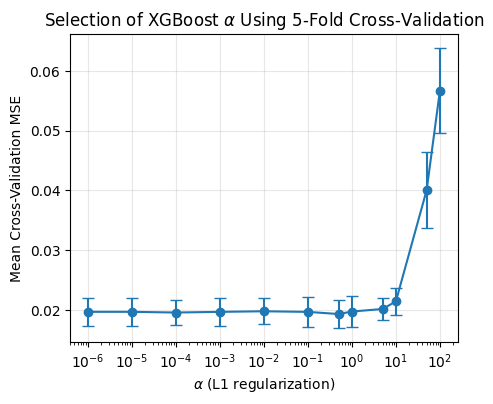

,Feature,Importance
0,PctIlleg,0.163956
1,PctKids2Par,0.143288
2,PctFam2Par,0.054363
3,NumIlleg,0.037723
4,racePctWhite,0.027464


In [43]:
# Define 5-fold cross-validation
cv = KFold(n_splits=5, shuffle=True, random_state=333)
# Create the imputation + XGBoost pipeline. The median imputer is fitted separately inside each cross-validation training fold, preventing data leakage.
pipeline = Pipeline([("imputer",SimpleImputer(strategy="median")),("xgb",XGBRegressor(objective="reg:squarederror", booster="gbtree", n_estimators=500, learning_rate=0.05, max_depth=3, subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0,random_state=333, n_jobs=1))])
# Candidate alpha values: reg_alpha is XGBoost's L1 regularization parameter.Alpha = 0 is included because cross-validation may determine that no L1 regularization gives the lowest validation error.
alpha_values = [0, 1e-5,1e-4,1e-3,1e-2,1e-1,0.5,1,5,10,50,100]
param_grid = {"xgb__reg_alpha": alpha_values}
# Select alpha using cross-validation
grid_search = GridSearchCV(estimator=pipeline,param_grid=param_grid,scoring="neg_mean_squared_error", cv=cv,n_jobs=-1,return_train_score=True)
grid_search.fit(X_train, y_train)
# Extract the best alpha and cross-validation MSE
best_alpha = grid_search.best_params_["xgb__reg_alpha"]
best_cv_mse = -grid_search.best_score_
print(f"Best alpha: {best_alpha}")
print(f"Best 5-fold CV MSE: {best_cv_mse:.6f}")
# Evaluate the selected model on the test set
# GridSearchCV automatically refits the complete pipeline onthe entire training set using the selected alpha.
best_xgb_model = grid_search.best_estimator_
y_train_pred = best_xgb_model.predict(X_train)
y_test_pred = best_xgb_model.predict(X_test)
train_mse = mean_squared_error(y_train, y_train_pred)
test_mse = mean_squared_error(y_test, y_test_pred)
print(f"Training MSE: {train_mse:.6f}",f"\nTest MSE: {test_mse:.6f}")
# Display all cross-validation results
cv_results = pd.DataFrame({"alpha": grid_search.cv_results_["param_xgb__reg_alpha"].astype(float), "Mean Training MSE": -grid_search.cv_results_["mean_train_score"],
    "Mean CV MSE": -grid_search.cv_results_["mean_test_score"], "CV MSE Standard Deviation": grid_search.cv_results_["std_test_score"]})
cv_results = cv_results.sort_values("alpha").reset_index(drop=True)
display(cv_results.style.format({"alpha": "{:.5g}","Mean Training MSE": "{:.6f}","Mean CV MSE": "{:.6f}", "CV MSE Standard Deviation": "{:.6f}"}))
# Plot alpha against cross-validation MSE
plot_results = cv_results.copy()
# A logarithmic x-axis cannot display zero, so alpha = 0 is placed slightly to the left of the smallest positive alpha.
smallest_positive_alpha = plot_results.loc[plot_results["alpha"] > 0, "alpha"].min()
plot_results["alpha_for_plot"] = plot_results["alpha"].replace(0,smallest_positive_alpha / 10)
plt.figure(figsize=(5, 4))
plt.errorbar(plot_results["alpha_for_plot"],plot_results["Mean CV MSE"], yerr=plot_results["CV MSE Standard Deviation"], marker="o", capsize=4)
plt.xscale("log")
plt.xlabel(r"$\alpha$ (L1 regularization)")
plt.ylabel("Mean Cross-Validation MSE")
plt.title(r"Selection of XGBoost $\alpha$ Using 5-Fold Cross-Validation")
plt.grid(alpha=0.3)
plt.show()
# Optional: display XGBoost feature importance
feature_names = X_train.columns
feature_importance = pd.DataFrame({"Feature": feature_names,"Importance": ( best_xgb_model.named_steps["xgb"].feature_importances_)})
feature_importance = (feature_importance.sort_values("Importance", ascending=False).reset_index(drop=True))
display(feature_importance.head().style.format({"Importance": "{:.6f}"}))